# Geometry-aware quantum cloud challenge: base template

Qiskit Fall Fest 2026, quanTA / USask. Bell pair `|Φ+>` between two designated ports on three
processor models, ideal / noisy / noisy + protection, with fidelity, cost and yield.

**How the pieces fit**

| Layer | Where | What you swap |
|---|---|---|
| Processor models | section 2 | graphs, ports, noise (`PROCESSORS`) |
| Transport | section 3 | how the pair gets from one port to the other (`TRANSPORTS`) |
| Protection | section 4 | checks, postselection, Pauli-frame tracking (`PROTECTIONS`) |
| Measurement | section 5 | XX / YY / ZZ, postselection, fidelity, cost metrics (`run_case`) |
| Core benchmark | section 6 | the nine cases |
| Playground | section 7 | grids and sweeps, kept apart from the core benchmark |

**Placeholders to replace with the organisers' common definitions:** the port pairs, the
2016 and hyperbolic noise numbers, and the exact hyperbolic graph. Each is marked `PLACEHOLDER`.

## 1. Configuration

In [ ]:
import warnings
from dataclasses import dataclass, field, replace

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import BackendSamplerV2
from qiskit.transpiler import CouplingMap, StagedPassManager, generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error, pauli_error, thermal_relaxation_error
from qiskit_ibm_runtime import fake_provider

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)

SEED = 7
SHOTS = 8192                      # per measurement basis (three bases per case)

# Optimisation level 1 on purpose. From level 2 up, Qiskit's ElidePermutations pass deletes
# explicit SWAPs and relabels the outputs instead, so the pair never physically reaches the
# port. `at_ports` in every result row checks this; try OPT_LEVEL = 2 and watch it flip.
OPT_LEVEL = 1

CONTEMPORARY_BACKEND = "FakeFez"  # Heron r2 heavy-hex. Try "FakeTorino", "FakeNighthawk" (square lattice)
CONTEMPORARY_PORT_DISTANCE = 6    # PLACEHOLDER: hops between the auto-picked contemporary ports
HYPERBOLIC = dict(p=7, q=3, rings=1)  # PLACEHOLDER: {p,q} tiling patch; rings=1 -> 35 qubits

# PLACEHOLDER ports. None = auto-pick (see section 2).
PORTS = {"ibm2016": (0, 4), "contemporary": None, "hyperbolic": None}

# Core benchmark strategy (section 6). Any names from TRANSPORTS / PROTECTIONS.
BASELINE_TRANSPORT = "swap_chain"
PROTECTED_TRANSPORT = "swap_chain"
PROTECTION = ["vacancy"]

## 2. Processor models

Every model is a `Processor`: an integer-labelled coupling graph, two ports, and either a
synthetic noise model or a backend that supplies target and noise together.

In [ ]:
@dataclass
class SyntheticNoise:
    """Depolarising gates + symmetric readout error, optional T1/T2 on gates. PLACEHOLDER numbers."""
    p1: float                 # 1q depolarising probability
    p2: float                 # 2q depolarising probability
    readout: float            # P(flip) on measurement
    t1: float | None = None   # seconds; None = no thermal relaxation
    t2: float | None = None
    t_1q: float = 50e-9
    t_2q: float = 300e-9

    def scaled(self, k):
        return replace(self, p1=min(self.p1 * k, 0.75), p2=min(self.p2 * k, 0.9),
                       readout=min(self.readout * k, 0.5))

    def build(self, two_qubit_gate):
        nm = NoiseModel(basis_gates=["rz", "sx", "x", two_qubit_gate])
        e1, e2 = depolarizing_error(self.p1, 1), depolarizing_error(self.p2, 2)
        if self.t1:
            r1 = thermal_relaxation_error(self.t1, self.t2, self.t_1q)
            r2 = thermal_relaxation_error(self.t1, self.t2, self.t_2q)
            e1, e2 = e1.compose(r1), e2.compose(r2.tensor(r2))
        nm.add_all_qubit_quantum_error(e1, ["sx", "x"])
        nm.add_all_qubit_quantum_error(e2, [two_qubit_gate])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - self.readout, self.readout],
                                                     [self.readout, 1 - self.readout]]))
        return nm

NOISE_2016 = SyntheticNoise(p1=2e-3, p2=3e-2, readout=4e-2)      # PLACEHOLDER, 2016-era ballpark
NOISE_MODERN = SyntheticNoise(p1=3e-4, p2=3e-3, readout=1e-2)    # PLACEHOLDER, Heron-era ballpark

@dataclass
class BiasedNoise:
    """Effective model of a noise-biased qubit (cat, 0-n Fock, post-selected dual-rail, or a
    replacement-type gate): Pauli errors with p_Z = eta * (p_X + p_Y). eta = 0.5 is unbiased.

    bias_preserving=True  -> CX is a native gate, so a Z error stays a Z error.
    bias_preserving=False -> CX is compiled as H.CZ.H and the Hadamards turn Z into X.
    p2 is the total error probability per two-qubit gate, split evenly over its two qubits."""
    p1: float
    p2: float
    readout: float
    eta: float = 100.0
    bias_preserving: bool = True

    @property
    def two_qubit_gate(self):
        return "cx" if self.bias_preserving else "cz"

    def _pauli(self, p):
        px = p / (2 * (self.eta + 1))
        return pauli_error([("X", px), ("Y", px), ("Z", p - 2 * px), ("I", 1 - p)])

    def build(self, two_qubit_gate):
        nm = NoiseModel(basis_gates=["rz", "sx", "x", two_qubit_gate])
        nm.add_all_qubit_quantum_error(self._pauli(self.p1), ["sx", "x"])
        e = self._pauli(self.p2 / 2)
        nm.add_all_qubit_quantum_error(e.tensor(e), [two_qubit_gate])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - self.readout, self.readout],
                                                     [self.readout, 1 - self.readout]]))
        return nm

@dataclass
class BiasedNoise:
    """Pauli errors with p_Z = eta * (p_X + p_Y). eta = 0.5 is unbiased."""
    p1: float
    p2: float
    readout: float
    eta: float = 100.0
    bias_preserving: bool = True

    @classmethod
    def like(cls, ref, eta=100.0, bias_preserving=True):
        """Same total error per gate and same readout error as a SyntheticNoise."""
        return cls(p1=0.75 * ref.p1, p2=0.9375 * ref.p2, readout=ref.readout,
                   eta=eta, bias_preserving=bias_preserving)

    @property
    def two_qubit_gate(self):
        return "cx" if self.bias_preserving else "cz"

    def scaled(self, k):
        return replace(self, p1=min(self.p1 * k, 0.75), p2=min(self.p2 * k, 0.9),
                       readout=min(self.readout * k, 0.5))

    def _pauli(self, p):
        px = p / (2 * (self.eta + 1))
        return pauli_error([("X", px), ("Y", px), ("Z", p - 2 * px), ("I", 1 - p)])

    def build(self, two_qubit_gate):
        nm = NoiseModel(basis_gates=["rz", "sx", "x", two_qubit_gate])
        nm.add_all_qubit_quantum_error(self._pauli(self.p1), ["sx", "x"])
        e = self._pauli(self.p2 / 2)
        nm.add_all_qubit_quantum_error(e.tensor(e), [two_qubit_gate])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - self.readout, self.readout],
                                                     [self.readout, 1 - self.readout]]))
        return nm


def distance_sweep(procs, transport="ghz_uncompute", protection=(), noise=NOISE_MODERN, max_hops=10, **kw):
    rows = []
    for proc in procs.values():
        same = proc.with_noise(noise)
        for d in range(1, min(nx.diameter(proc.graph), max_hops) + 1):
            try:
                r = run_case(same.with_ports(*pair_at_distance(proc.graph, d)), transport, protection, **kw)
                rows.append(r)
            except (Incompatible, ValueError):
                pass
    return pd.DataFrame(rows)


def scale_axis(ax, scales):
    """Log x axis with one plain tick per simulated noise scale."""
    ax.set_xscale("log")
    ax.set_xticks(list(scales), [f"{k:g}" for k in scales])
    ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
    ax.set_xlabel("noise scale (x NOISE_MODERN)")


def noise_sweep(proc, strategies, scales=(0.25, 0.5, 1, 2, 4, 8), base=NOISE_MODERN, **kw):
    rows = []
    for k in scales:
        scaled = proc.with_noise(base.scaled(k))
        for name, (t, prot) in strategies.items():
            rows.append(dict(scale=k, strategy=name, **run_case(scaled, t, prot, **kw)))
    return pd.DataFrame(rows)
NOISE_2016 = SyntheticNoise(p1=2e-3, p2=3e-2, readout=4e-2)      # PLACEHOLDER, 2016-era ballpark
NOISE_MODERN = SyntheticNoise(p1=3e-4, p2=3e-3, readout=1e-2)    # PLACEHOLDER, Heron-era ballpark


@dataclass
class Processor:
    key: str
    label: str
    graph: nx.Graph
    ports: tuple
    two_qubit_gate: str = "cx"
    noise: SyntheticNoise | None = None
    backend: object | None = None       # fake or real backend; overrides `noise` and gate set
    pos: dict | None = None
    _sims: dict = field(default_factory=dict, repr=False)

    @property
    def n(self):
        return self.graph.number_of_nodes()

    @property
    def distance(self):
        return nx.shortest_path_length(self.graph, *self.ports)

    def path(self, weight=None):
        return nx.shortest_path(self.graph, *self.ports, weight=weight)

    def pass_manager(self, opt_level=None, **kw):
        opt_level = OPT_LEVEL if opt_level is None else opt_level
        common = dict(initial_layout=list(range(self.n)), seed_transpiler=SEED, **kw)
        if self.backend is not None:
            return generate_preset_pass_manager(opt_level, backend=self.backend, **common)
        cm = CouplingMap([e for u, v in self.graph.edges for e in ((u, v), (v, u))])
        return generate_preset_pass_manager(
            opt_level, coupling_map=cm, basis_gates=["rz", "sx", "x", self.two_qubit_gate], **common)

    def simulator(self, noisy):
        if noisy not in self._sims:
            if not noisy:
                sim = AerSimulator()
            elif self.backend is not None:
                sim = AerSimulator.from_backend(self.backend)
            else:
                sim = AerSimulator(noise_model=self.noise.build(self.two_qubit_gate))
            self._sims[noisy] = sim
        return self._sims[noisy]

    def with_ports(self, a, b):
        return replace(self, ports=(a, b), _sims=self._sims)

    def with_noise(self, noise, label=None):
        """Same graph, synthetic noise. Use to separate connectivity from noise/gate-set effects."""
        return replace(self, noise=noise, backend=None, label=label or self.label, _sims={},
                       two_qubit_gate=getattr(noise, "two_qubit_gate", "cz"))

In [ ]:
def pair_at_distance(G, d):
    """Deterministic pair of nodes exactly d hops apart (lowest indices first)."""
    for u in sorted(G):
        hits = sorted(v for v, k in nx.single_source_shortest_path_length(G, u, cutoff=d).items() if k == d)
        if hits:
            return u, hits[0]
    raise ValueError(f"no pair at distance {d}")


def farthest_pair(G):
    ecc = nx.eccentricity(G)
    u = min(n for n in G if ecc[n] == max(ecc.values()))
    dist = nx.single_source_shortest_path_length(G, u)
    return u, min(v for v in G if dist[v] == ecc[u])


def hyperbolic_patch(p=7, q=3, rings=1):
    """Finite patch of the {p,q} hyperbolic tiling: a central p-gon plus `rings` layers of
    edge-adjacent p-gons, built by reflecting polygons across their edges in the Poincare disk.
    Returns (graph, positions). Vertices are qubits, polygon edges are couplers."""
    r0 = np.sqrt(np.cos(np.pi / p + np.pi / q) / np.cos(np.pi / p - np.pi / q))
    base = [r0 * np.exp(2j * np.pi * k / p) for k in range(p)]

    def reflect(z, a, b):  # inversion in the geodesic (circle orthogonal to the unit circle) through a, b
        cx, cy = np.linalg.solve([[a.real, a.imag], [b.real, b.imag]],
                                 [(1 + abs(a) ** 2) / 2, (1 + abs(b) ** 2) / 2])
        c = cx + 1j * cy
        return c + (abs(c) ** 2 - 1) / np.conj(z - c)

    key = lambda z: (round(z.real, 6) + 0.0, round(z.imag, 6) + 0.0)
    polys, frontier = {key(0j): base}, [(0j, base)]
    for _ in range(rings):
        new = []
        for centre, vs in frontier:
            for k in range(p):
                a, b = vs[k], vs[(k + 1) % p]
                c2 = reflect(centre, a, b)
                if key(c2) not in polys:
                    polys[key(c2)] = [reflect(v, a, b) for v in vs]
                    new.append((c2, polys[key(c2)]))
        frontier = new

    pts = {}
    for vs in polys.values():
        for v in vs:
            pts.setdefault(key(v), v)
    order = sorted(pts, key=lambda k: (round(abs(pts[k]), 4), np.angle(pts[k]) % (2 * np.pi)))
    index = {k: i for i, k in enumerate(order)}
    G = nx.Graph()
    G.add_nodes_from(range(len(order)))
    for vs in polys.values():
        for k in range(p):
            G.add_edge(index[key(vs[k])], index[key(vs[(k + 1) % p])])
    assert max(dict(G.degree).values()) <= q, "vertex merge failed; lower `rings` or loosen rounding"
    return G, {index[k]: (pts[k].real, pts[k].imag) for k in order}


def build_processors():
    procs = {}

    # --- 2016-inspired: the five-qubit "bowtie" (IBM QX2 / Yorktown) graph -------------------
    G = nx.Graph([(0, 1), (0, 2), (1, 2), (2, 3), (2, 4), (3, 4)])
    pos = {0: (-1, 1), 1: (-1, -1), 2: (0, 0), 3: (1, -1), 4: (1, 1)}
    procs["ibm2016"] = Processor("ibm2016", "2016-inspired", G, PORTS["ibm2016"], "cx", NOISE_2016, pos=pos)

    # --- Contemporary IBM-style: fake backend = calibration snapshot + native target ---------
    backend = getattr(fake_provider, CONTEMPORARY_BACKEND)()
    G = nx.Graph()
    G.add_nodes_from(range(backend.num_qubits))
    G.add_edges_from(backend.coupling_map.get_edges())
    ports = PORTS["contemporary"] or pair_at_distance(G, CONTEMPORARY_PORT_DISTANCE)
    gate2 = next(g for g in ("cz", "ecr", "cx") if g in backend.operation_names)
    procs["contemporary"] = Processor("contemporary", f"Contemporary ({CONTEMPORARY_BACKEND})", G, ports,
                                      gate2, backend=backend, pos=nx.kamada_kawai_layout(G))

    # --- Hyperbolic-inspired: finite {p,q} patch, circuit-level model only -------------------
    G, pos = hyperbolic_patch(**HYPERBOLIC)
    ports = PORTS["hyperbolic"] or farthest_pair(G)
    name = "Hyperbolic {%d,%d}" % (HYPERBOLIC["p"], HYPERBOLIC["q"])
    procs["hyperbolic"] = Processor("hyperbolic", name, G, ports, "cz", NOISE_MODERN, pos=pos)
    return procs


PROCESSORS = build_processors()


def graph_metrics(procs):
    rows = []
    for p in procs.values():
        G, deg = p.graph, dict(p.graph.degree)
        rows.append(dict(model=p.label, qubits=p.n, couplers=G.number_of_edges(),
                         max_degree=max(deg.values()), mean_degree=np.mean(list(deg.values())),
                         girth=nx.girth(G), diameter=nx.diameter(G),
                         mean_distance=nx.average_shortest_path_length(G),
                         ports=p.ports, port_distance=p.distance))
    return pd.DataFrame(rows).set_index("model")


graph_metrics(PROCESSORS)

,qubits,couplers,max_degree,mean_degree,girth,diameter,mean_distance,ports,port_distance
model,,,,,,,,,
2016-inspired,5,6,4,2.4000,3,2,1.4000,"(0, 4)",2
Contemporary (FakeFez),156,176,3,2.2564,12,32,12.6356,"(0, 6)",6
"Hyperbolic {7,3}",35,42,3,2.4000,7,8,4.4000,"(14, 31)",8


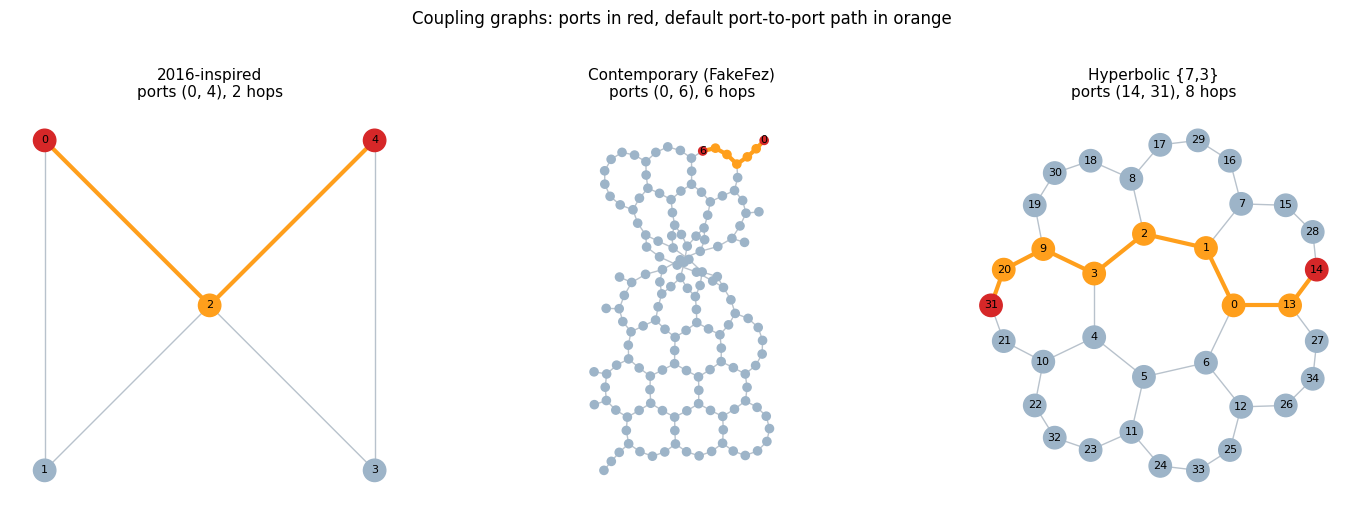

In [ ]:
def draw_processors(procs, figsize=(15, 5)):
    fig, axes = plt.subplots(1, len(procs), figsize=figsize)
    for ax, p in zip(np.atleast_1d(axes), procs.values()):
        path = p.path()
        on_path = set(path[1:-1])
        colors = ["#d62728" if n in p.ports else "#ff9f1c" if n in on_path else "#9db4c8" for n in p.graph]
        small = p.n > 60
        nx.draw_networkx_edges(p.graph, p.pos, ax=ax, edge_color="#b8c2cc", width=1)
        nx.draw_networkx_edges(p.graph, p.pos, ax=ax, edgelist=list(zip(path, path[1:])),
                               edge_color="#ff9f1c", width=3)
        nx.draw_networkx_nodes(p.graph, p.pos, ax=ax, node_color=colors, node_size=35 if small else 260)
        labels = {n: n for n in p.graph if not small or n in p.ports}
        nx.draw_networkx_labels(p.graph, p.pos, labels, ax=ax, font_size=8)
        ax.set_title(f"{p.label}\nports {p.ports}, {p.distance} hops", fontsize=11)
        ax.set_aspect("equal")
        ax.axis("off")
    fig.suptitle("Coupling graphs: ports in red, default port-to-port path in orange", y=1.02)
    plt.tight_layout()
    return fig


draw_processors(PROCESSORS);

## 3. Transport: getting the pair to the ports

Circuits are written directly on **physical** qubits, so what you write is what runs; the
transpiler only translates to the native gate set and tidies up. A `Build` carries the circuit
plus the bookkeeping a protection scheme needs.

With `d` = hops between the ports:

| Transport | Idea | 2q gates | Path qubits afterwards |
|---|---|---|---|
| `swap_chain` | Bell pair at one end, SWAP one half along the path (what a router does) | `3d - 2` | `|0>`, reusable |
| `swap_middle_out` | Bell pair mid-path, SWAP both halves outward | `3d - 2`, about half the depth | `|0>`, reusable |
| `ghz_uncompute` | CX ladder to a GHZ state, then un-ladder the interior | `2d - 1` | `|0>`, reusable |
| `ghz_measure` | GHZ ladder from the middle, measure the interior in X, fix the sign in software | `d` | consumed |
| `sabre` | Hand the transpiler a long-range CX and let SABRE route it | router's choice | unknown |

In [ ]:
class Incompatible(Exception):
    """Raised when a protection cannot be applied after the chosen transport."""


class Build:
    """A circuit on physical qubits plus what post-processing needs.

    measure(q, basis) returns a bit index. Use those indices in:
      flags    list of bit-index groups; a shot is kept only if every group has even parity
      frame_z  bit indices whose parity means "a Z is owed on port A" (flips its X/Y outcomes)
      frame_x  bit indices whose parity means "an X is owed on port A" (flips its Z/Y outcomes)
    zero       path qubits known to be |0> and free to reuse as ancillas
    A check measured after the frame is non-empty must fold the frame into its flag group
    (see p_bus_zz / p_bus_xx), otherwise a correct but sign-flipped pair gets thrown away.
    """

    def __init__(self, proc, path):
        self.proc, self.path = proc, list(path)
        self.a, self.b = self.path[0], self.path[-1]
        self.interior = self.path[1:-1]
        self.qc = QuantumCircuit(QuantumRegister(proc.n, "q"), ClassicalRegister(2, "port"))
        self.zero, self.deferred = set(), []
        self.flags, self.frame_z, self.frame_x = [], [], []
        self.nbits = 2

    @staticmethod
    def _rotate(qc, q, basis):
        if basis == "Y":
            qc.sdg(q)
        if basis in "XY":
            qc.h(q)

    def measure(self, q, basis="Z", reset=False):
        """Measure q. With reset=True it happens now and q returns to |0>; otherwise it is
        deferred to the end of the circuit (cheaper to simulate, no idle time after it)."""
        creg = ClassicalRegister(1, f"m{self.nbits - 2}")
        self.qc.add_register(creg)
        if reset:
            self._rotate(self.qc, q, basis)
            self.qc.measure(q, creg[0])
            self.qc.reset(q)
            self.zero.add(q)
        else:
            self.deferred.append((q, basis, creg))
            self.zero.discard(q)
        self.nbits += 1
        return self.nbits - 1

    def finalize(self, basis):
        """Full circuit measuring both ports in `basis` ("X", "Y" or "Z")."""
        qc = self.qc.copy()
        for q, bs, creg in self.deferred:
            self._rotate(qc, q, bs)
            qc.measure(q, creg[0])
        for i, q in enumerate((self.a, self.b)):
            self._rotate(qc, q, basis)
            qc.measure(q, qc.cregs[0][i])
        return qc


def t_swap_chain(b):
    p, qc = b.path, b.qc
    qc.h(p[0])
    qc.cx(p[0], p[1])
    for i in range(1, len(p) - 1):
        qc.swap(p[i], p[i + 1])
    b.zero = set(b.interior)


def t_swap_middle_out(b):
    p, qc = b.path, b.qc
    i = (len(p) - 2) // 2
    qc.h(p[i])
    qc.cx(p[i], p[i + 1])
    for k in range(i, 0, -1):
        qc.swap(p[k], p[k - 1])
    for k in range(i + 1, len(p) - 1):
        qc.swap(p[k], p[k + 1])
    b.zero = set(b.interior)


def t_ghz_uncompute(b):
    p, qc = b.path, b.qc
    qc.h(p[0])
    for i in range(len(p) - 1):
        qc.cx(p[i], p[i + 1])
    for i in range(len(p) - 2, 0, -1):
        qc.cx(p[i - 1], p[i])
    b.zero = set(b.interior)


def t_ghz_measure(b):
    p, qc = b.path, b.qc
    m = (len(p) - 1) // 2
    qc.h(p[m])
    for i in range(m, len(p) - 1):
        qc.cx(p[i], p[i + 1])
    for i in range(m, 0, -1):
        qc.cx(p[i], p[i - 1])
    # An X-basis outcome of 1 on any interior qubit turns Phi+ into Phi-: track it, don't fix it.
    b.frame_z += [b.measure(q, "X") for q in b.interior]


def t_sabre(b):
    b.qc.h(b.a)
    b.qc.cx(b.a, b.b)      # not on an edge unless d = 1; the routing stage inserts the SWAPs


TRANSPORTS = {
    "swap_chain": t_swap_chain,
    "swap_middle_out": t_swap_middle_out,
    "ghz_uncompute": t_ghz_uncompute,
    "ghz_measure": t_ghz_measure,
    "sabre": t_sabre,
}

## 4. Protection strategies

`|Φ+>` is the unique +1 eigenstate of `XX` and `ZZ` on the ports, so those are the two checks
worth measuring. The ports are not neighbours, so each check has to travel along the graph:
that cost is where the geometry enters.

| Protection | Detects | Extra 2q gates | Notes |
|---|---|---|---|
| `none` | nothing | 0 | baseline |
| `vacancy` | excitations left on path qubits that should be empty | 0 | free postselection |
| `bus_zz` | bit flips on the ports (`ZZ = -1`) | `d` | interior qubits as a parity bus |
| `bus_xx` | phase flips on the ports (`XX = -1`) | `d` | interior prepared as a GHZ ancilla |

Protections are a list and are applied in order: `["bus_zz", "bus_xx"]` measures both
stabilizers, with a mid-circuit measure-and-reset of the bus in between. Each takes
`reuse=True` when a later protection still needs the path qubits.

In [ ]:
def _need_bus(b, name):
    if not b.interior:
        raise Incompatible(f"{name}: ports are adjacent, no interior qubit to use as a bus")
    if not set(b.interior) <= b.zero:
        raise Incompatible(f"{name}: path interior is not in |0> after this transport")
    return b.interior


def p_none(b, reuse=False):
    pass


def p_vacancy(b, reuse=False):
    """Every path qubit the transport vacated should read 0. Zero extra gates."""
    for q in _need_bus(b, "vacancy"):
        b.flags.append([b.measure(q, "Z", reset=reuse)])


def p_bus_zz(b, reuse=False):
    """ZZ parity of the ports, accumulated on the last bus qubit. The other bus qubits end up
    holding copies of port A's Z value; measuring them in X releases them at the price of a
    tracked Z on port A."""
    bus, qc = _need_bus(b, "bus_zz"), b.qc
    qc.cx(b.a, bus[0])
    for u, v in zip(bus, bus[1:]):
        qc.cx(u, v)
    qc.cx(b.b, bus[-1])
    zz = [b.measure(bus[-1], "Z", reset=reuse)]
    b.flags.append(zz + list(b.frame_x))        # an owed X on port A flips ZZ: fold it in
    b.frame_z += [b.measure(q, "X", reset=reuse) for q in bus[:-1]]


def p_bus_xx(b, reuse=False):
    """XX parity of the ports. The bus becomes a GHZ ancilla (+1 eigenstate of X on every bus
    qubit); two CXs attach X_a X_b to that operator, so the parity of the bus X outcomes is XX."""
    bus, qc = _need_bus(b, "bus_xx"), b.qc
    qc.h(bus[0])
    for u, v in zip(bus, bus[1:]):
        qc.cx(u, v)
    qc.cx(bus[0], b.a)
    qc.cx(bus[-1], b.b)
    xx = [b.measure(q, "X", reset=reuse) for q in bus]
    b.flags.append(xx + list(b.frame_z))        # an owed Z on port A flips XX: fold it in


PROTECTIONS = {
    "none": p_none,
    "vacancy": p_vacancy,
    "bus_zz": p_bus_zz,
    "bus_xx": p_bus_xx,
}

# To add your own: write f(b, reuse=False) that appends gates to b.qc on coupled qubits, calls
# b.measure(...) and files the returned bit indices under b.flags / b.frame_z / b.frame_x, then
# register it above. The self-test in section 5 tells you immediately if the ideal case breaks.

# Section 4b. Mitigation blocks

In [ ]:
from qiskit.circuit import Gate

if "MITIGATION" not in globals():
    MITIGATION = ["readout"]          # for the core benchmark; [] switches it off, try ["readout", "zne"]


class Mitigation:
    """Base block. Override any of the three hooks; the defaults change nothing."""
    scales = (1,)                 # noise scale factors to run the circuits at
    calibration_shots = 1         # shots for calibration circuits, as a multiple of the experiment's

    def calibration(self, proc, ports):
        """Extra circuits to run alongside the experiment, written on physical qubits."""
        return []

    def port_weights(self, calibration_arrays):
        """(weights, relative variance). weights[x, port] is the value given to raw outcome x."""
        return None

    def combine(self, by_scale, current):
        """Merge the results measured at each noise scale into one."""
        return current


class ReadoutCorrection(Mitigation):
    """Measure how often each port misreads |0> and |1>, then invert that 2x2 table per port.

    With e0 = P(read 1 | 0) and e1 = P(read 0 | 1), counting an outcome 0 as
    +(1 + e0 - e1) / (1 - e0 - e1) and an outcome 1 as -(1 - e0 + e1) / (1 - e0 - e1), in place
    of +1 and -1, makes the average of a port, and of a product of ports, unbiased."""
    calibration_shots = 8

    def calibration(self, proc, ports):
        circuits = []
        for bit in (0, 1):
            qc = QuantumCircuit(QuantumRegister(proc.n, "q"), ClassicalRegister(2, "port"))
            if bit:
                qc.x(list(ports))
            qc.measure(list(ports), qc.cregs[0])
            circuits.append(qc)
        return circuits

    def port_weights(self, calibration_arrays):
        zeros, ones = calibration_arrays
        e0, e1 = zeros.mean(axis=0), 1 - ones.mean(axis=0)
        det = 1 - e0 - e1
        weights = np.stack([(1 + e0 - e1) / det, -(1 - e0 + e1) / det])
        relative_variance = ((e0 * (1 - e0) + e1 * (1 - e1)) / len(zeros) / det**2).sum()
        return weights, relative_variance


class ZeroNoiseExtrapolation(Mitigation):
    """Rerun with every two-qubit gate G replaced by G (G^-1 G)^k. The logic is unchanged and the
    gate noise is multiplied by 1 + 2k. Fit each correlator against that scale, read off zero."""

    def __init__(self, scales=(1, 3, 5)):
        self.scales = scales

    @staticmethod
    def fold(circuit, scale):
        if scale == 1:
            return circuit
        folded = circuit.copy_empty_like()
        for inst in circuit.data:
            folded.append(inst)
            if isinstance(inst.operation, Gate) and inst.operation.num_qubits == 2:
                for _ in range((scale - 1) // 2):
                    folded.barrier(*inst.qubits)          # keeps anything downstream from cancelling the pair
                    folded.append(inst.operation.inverse(), inst.qubits)
                    folded.barrier(*inst.qubits)
                    folded.append(inst.operation, inst.qubits)
        return folded

    @staticmethod
    def zero_noise(x, y, err):
        """Value at x = 0 and its standard error: exponential decay if every point is positive, else a line."""
        err = np.maximum(err, 1e-6)
        if np.all(y > 0):
            coef, cov = np.polyfit(x, np.log(y), 1, w=y / err, cov="unscaled")
            return np.exp(coef[1]), np.exp(coef[1]) * np.sqrt(cov[1, 1])
        coef, cov = np.polyfit(x, y, 1, w=1 / err, cov="unscaled")
        return coef[1], np.sqrt(cov[1, 1])

    def combine(self, by_scale, current):
        x = np.array(sorted(by_scale), dtype=float)
        out, errs = dict(current), {}
        for key, sign in (("XX", 1), ("YY", -1), ("ZZ", 1)):          # signs that make all three positive
            y = sign * np.array([by_scale[s][key] for s in x])
            value, errs[key] = self.zero_noise(x, y, np.array([by_scale[s]["_err"][key] for s in x]))
            out[key] = sign * value
        out["F"] = (1 + out["XX"] - out["YY"] + out["ZZ"]) / 4
        out["F_err"] = np.sqrt(sum(e**2 for e in errs.values())) / 4
        out["_err"] = errs
        return out


MITIGATIONS = {
    "none": Mitigation(),
    "readout": ReadoutCorrection(),
    "zne": ZeroNoiseExtrapolation(scales=(1, 3, 5)),
}

## 5. Measurement, fidelity and cost

`F(Φ+) = [1 + <XX> - <YY> + <ZZ>] / 4`, each correlator from its own circuit with `SHOTS` shots.
Postselection and the Pauli frame are applied per shot before the correlators are formed.

In [ ]:
BASES = ("X", "Y", "Z")


def build_case(proc, transport, protection=(), path=None):
    b = Build(proc, path or proc.path())
    TRANSPORTS[transport](b)
    protection = [protection] if isinstance(protection, str) else list(protection)
    for i, name in enumerate(protection):
        PROTECTIONS[name](b, reuse=i < len(protection) - 1)
    return b


def _method(tc):
    """Terminal-measurement circuits on few qubits: density matrix (one exact evolution, then
    sampling). Mid-circuit reset forces shot-by-shot trajectories, where statevector is quickest;
    on a fake backend that is roughly a minute per case at 8192 shots. Wide circuits: MPS."""
    active = {tc.find_bit(q).index for inst in tc.data for q in inst.qubits}
    if "reset" in tc.count_ops():
        return "statevector" if len(active) <= 14 else "matrix_product_state"
    return "density_matrix" if len(active) <= 10 else "matrix_product_state"


def analyse(arrays, b, weights=None):
    """arrays: {basis: bool array (shots, nbits)}; columns 0, 1 are the ports.
    weights[x, port] is the value given to raw outcome x on that port; the default is +1 / -1."""
    if weights is None:
        weights = np.array([[1.0, 1.0], [-1.0, -1.0]])
    out, errs, kept, total = {}, {}, 0, 0
    for basis, arr in arrays.items():
        accept = np.ones(len(arr), dtype=bool)
        for group in b.flags:
            accept &= ~np.logical_xor.reduce(arr[:, group], axis=1)
        flip = np.zeros(len(arr), dtype=bool)               # Pauli frame: a sign owed on port A
        if basis in "XY" and b.frame_z:
            flip ^= np.logical_xor.reduce(arr[:, b.frame_z], axis=1)
        if basis in "ZY" and b.frame_x:
            flip ^= np.logical_xor.reduce(arr[:, b.frame_x], axis=1)
        value = weights[arr[:, 0].astype(int), 0] * weights[arr[:, 1].astype(int), 1] * (1 - 2 * flip)
        value = value[accept]
        n = len(value)
        out[basis * 2] = value.mean() if n else np.nan
        errs[basis * 2] = value.std() / np.sqrt(n) if n else np.nan
        kept, total = kept + n, total + len(arr)
    out["F"] = (1 + out["XX"] - out["YY"] + out["ZZ"]) / 4
    out["F_err"] = np.sqrt(sum(e**2 for e in errs.values())) / 4      # standard error, propagated
    out["accept"] = kept / total
    out["discarded"] = total - kept
    out["_err"] = errs
    return out


def run_case(proc, transport, protection=(), noisy=True, shots=None, path=None, opt_level=None,
             label=None, sampler=None, keep_circuits=False, mitigation=(), **transpile_kw):
    """One row of the comparison. Pass `sampler` (any SamplerV2) to run on a real backend.
    F is always the unmitigated fidelity of the kept shots; `mitigation` adds F_mit beside it."""
    shots = shots or SHOTS
    b = build_case(proc, transport, protection, path)
    pm = proc.pass_manager(opt_level, **transpile_kw)
    logical = [b.finalize(basis) for basis in BASES]
    tcs = pm.run(logical)

    names = [mitigation] if isinstance(mitigation, str) else list(mitigation)
    blocks = [MITIGATIONS[name] for name in names]
    scales = sorted({1} | {s for m in blocks for s in m.scales})
    pubs = [(ZeroNoiseExtrapolation.fold(tc, s), None, shots) for s in scales for tc in tcs]
    calibration = [pm.run(m.calibration(proc, (b.a, b.b))) for m in blocks]
    pubs += [(c, None, shots * m.calibration_shots) for m, group in zip(blocks, calibration) for c in group]

    if sampler is None:
        sim = proc.simulator(noisy)
        sim.set_options(method=_method(tcs[-1]) if noisy else "automatic")
        sampler = BackendSamplerV2(backend=sim, options={"seed_simulator": SEED})
    data = [r.join_data().to_bool_array(order="little") for r in sampler.run(pubs).result()]
    k = len(BASES)
    arrays = {s: dict(zip(BASES, data[i * k:(i + 1) * k])) for i, s in enumerate(scales)}
    raw = analyse(arrays[1], b)

    tc = tcs[-1]
    routed = StagedPassManager(["init", "layout", "routing"], init=pm.init, layout=pm.layout,
                               routing=pm.routing).run(logical[-1])
    active = {tc.find_bit(q).index for inst in tc.data for q in inst.qubits}
    final = tc.layout.final_index_layout()
    prot = [protection] if isinstance(protection, str) else list(protection)
    row = dict(model=proc.label, case=label or ("noisy" if noisy else "ideal"), transport=transport,
               protection="+".join(prot) or "none", mitigation="+".join(names) or "none",
               hops=len(b.path) - 1)
    row.update({key: raw[key] for key in ("XX", "YY", "ZZ", "F", "F_err")})

    if blocks:
        weights, calibration_variance, position = None, 0.0, len(scales) * k
        for m, group in zip(blocks, calibration):
            learned = m.port_weights(data[position:position + len(group)])
            position += len(group)
            if learned is not None:
                weights, calibration_variance = learned
        by_scale = {s: analyse(arrays[s], b, weights) for s in scales}
        mitigated = by_scale[1]
        for m in blocks:
            mitigated = m.combine(by_scale, mitigated)
        scale_error = (4 * mitigated["F"] - 1) / 4 * np.sqrt(calibration_variance)
        row.update(F_mit=mitigated["F"], F_mit_err=np.hypot(mitigated["F_err"], scale_error))

    row.update(accept=raw["accept"], discarded=raw["discarded"])
    row.update(depth=tc.depth(), twoq=tc.num_nonlocal_gates(), swaps=routed.count_ops().get("swap", 0),
               qubits=len(active), ancillas=len(active) - 2,
               at_ports=(final[b.a], final[b.b]) == (b.a, b.b))
    if keep_circuits:
        row.update(logical=logical[-1], transpiled=tc)
    return row


def show_circuit(proc, transport, protection=(), transpiled=True, **kw):
    """Draw only the wires in use (the full register is mostly idle qubits)."""
    row = run_case(proc, transport, protection, noisy=False, shots=16, keep_circuits=True)
    qc = row["transpiled" if transpiled else "logical"]
    return qc.draw("mpl", idle_wires=False, fold=40, **kw)

### Self-test

Every transport x protection pair, on every model, without noise. Anything that does not give
`F = 1` with every shot accepted and the pair sitting on the ports is a bug in a strategy, not
physics. Rerun after adding anything to the registries.

In [ ]:
def self_test(procs=PROCESSORS, shots=512):
    rows = []
    combos = [[k] for k in PROTECTIONS if k != "none"] + [["bus_zz", "bus_xx"], ["bus_xx", "bus_zz", "vacancy"]]
    for proc in procs.values():
        for t in TRANSPORTS:
            for prot in [[]] + combos:
                try:
                    r = run_case(proc, t, prot, noisy=False, shots=shots)
                    ok = abs(r["F"] - 1) < 1e-9 and r["accept"] == 1 and (r["at_ports"] or t == "sabre")
                    rows.append(dict(model=proc.key, transport=t, protection=r["protection"],
                                     status="ok" if ok else "FAIL", F=r["F"], at_ports=r["at_ports"]))
                except Incompatible:
                    rows.append(dict(model=proc.key, transport=t, protection="+".join(prot),
                                     status="n/a", F=np.nan, at_ports=None))
    df = pd.DataFrame(rows)
    assert not (df.status == "FAIL").any(), df[df.status == "FAIL"]
    return df


st = self_test()
print(st.status.value_counts().to_string())
st.pivot_table(index=["transport", "protection"], columns="model", values="status", aggfunc="first")

status
ok     60
n/a    30


model                                 contemporary hyperbolic ibm2016
transport       protection                                           
ghz_measure     bus_xx                         n/a        n/a     n/a
                bus_xx+bus_zz+vacancy          n/a        n/a     n/a
                bus_zz                         n/a        n/a     n/a
                bus_zz+bus_xx                  n/a        n/a     n/a
                none                            ok         ok      ok
                vacancy                        n/a        n/a     n/a
ghz_uncompute   bus_xx                          ok         ok      ok
                bus_xx+bus_zz+vacancy           ok         ok      ok
                bus_zz                          ok         ok      ok
                bus_zz+bus_xx                   ok         ok      ok
                none                            ok         ok      ok
                vacancy                         ok         ok      ok
sabre           bus_xx                         n/a        n/a     n/a
                bus_xx+bus_zz+vacancy          n/a        n/a     n/a
                bus_zz                         n/a        n/a     n/a
                bus_zz+bus_xx                  n/a        n/a     n/a
                none                            ok         ok      ok
                vacancy                        n/a        n/a     n/a
swap_chain      bus_xx                          ok         ok      ok
                bus_xx+bus_zz+vacancy           ok         ok      ok
                bus_zz                          ok         ok      ok
                bus_zz+bus_xx                   ok         ok      ok
                none                            ok         ok      ok
                vacancy                         ok         ok      ok
swap_middle_out bus_xx                          ok         ok      ok
                bus_xx+bus_zz+vacancy           ok         ok      ok
                bus_zz                          ok         ok      ok
                bus_zz+bus_xx                   ok         ok      ok
                none                            ok         ok      ok
                vacancy                         ok         ok      ok

## 6. Core benchmark: the nine cases

In [ ]:
def core_benchmark(procs=PROCESSORS, mitigation=None):
    mitigation = MITIGATION if mitigation is None else mitigation
    rows, n = [], 1
    for proc in procs.values():
        for label, transport, prot, noisy in [
            ("ideal baseline", BASELINE_TRANSPORT, [], False),
            ("noisy baseline", BASELINE_TRANSPORT, [], True),
            ("noisy + protection", PROTECTED_TRANSPORT, PROTECTION, True),
        ]:
            rows.append(dict(n=n, **run_case(proc, transport, prot, noisy=noisy, label=label,
                                             mitigation=mitigation)))
            n += 1
    return pd.DataFrame(rows).set_index("n")


core = core_benchmark()
core.to_csv("core_benchmark.csv")
display(core)

,model,case,transport,protection,mitigation,hops,XX,YY,ZZ,F,F_err,F_mit,F_mit_err,accept,discarded,depth,twoq,swaps,qubits,ancillas,at_ports
n,,,,,,,,,,,,,,,,,,,,,
1,2016-inspired,ideal baseline,swap_chain,none,readout,2,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0,8,4,1,3,1,True
2,2016-inspired,noisy baseline,swap_chain,none,readout,2,0.7527,-0.7544,0.7454,0.8131,0.0032,0.9155,0.0039,1.0000,0,8,4,1,3,1,True
3,2016-inspired,noisy + protection,swap_chain,vacancy,readout,2,0.7622,-0.7653,0.7711,0.8246,0.0032,0.9291,0.0040,0.9207,1950,8,4,1,3,1,True
4,Contemporary (FakeFez),ideal baseline,swap_chain,none,readout,6,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0,37,16,5,7,5,True
5,Contemporary (FakeFez),noisy baseline,swap_chain,none,readout,6,0.8313,-0.8572,0.8459,0.8836,0.0026,0.9077,0.0027,1.0000,0,37,16,5,7,5,True
6,Contemporary (FakeFez),noisy + protection,swap_chain,vacancy,readout,6,0.8800,-0.9000,0.8922,0.9181,0.0023,0.9435,0.0024,0.9035,2372,37,16,5,7,5,True
7,"Hyperbolic {7,3}",ideal baseline,swap_chain,none,readout,8,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0,49,22,7,9,7,True
8,"Hyperbolic {7,3}",noisy baseline,swap_chain,none,readout,8,0.8933,-0.8997,0.8921,0.9213,0.0021,0.9490,0.0023,1.0000,0,49,22,7,9,7,True
9,"Hyperbolic {7,3}",noisy + protection,swap_chain,vacancy,readout,8,0.9161,-0.9192,0.9241,0.9399,0.0020,0.9683,0.0021,0.8992,2478,49,22,7,9,7,True


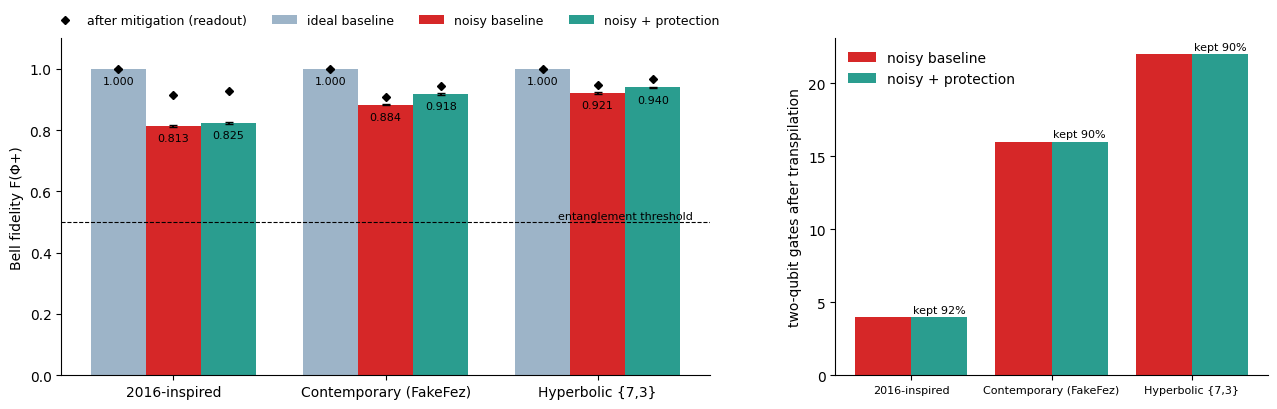

In [ ]:
def plot_core(df):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[3, 2]))
    cases = list(df.case.unique())
    models = list(df.model.unique())
    colors = ["#9db4c8", "#d62728", "#2a9d8f"]
    w = 0.26
    for i, case in enumerate(cases):
        sub = df[df.case == case].set_index("model").loc[models]
        x = np.arange(len(models)) + (i - 1) * w
        ax1.bar(x, sub.F, w, yerr=sub.F_err, capsize=3, color=colors[i], label=case)
        for xi, f in zip(x, sub.F):
            ax1.text(xi, f - 0.05, f"{f:.3f}", ha="center", fontsize=8)
        if "F_mit" in sub:
            ax1.plot(x, sub.F_mit, "D", color="k", ms=4, zorder=3,
                     label=f"after mitigation ({sub.mitigation.iloc[0]})" if i == 0 else None)
    ax1.axhline(0.5, color="k", lw=0.8, ls="--")
    ax1.text(len(models) - 0.55, 0.51, "entanglement threshold", fontsize=8, ha="right")
    ax1.set_xticks(np.arange(len(models)), models)
    ax1.set_ylim(0, 1.1)
    ax1.set_ylabel("Bell fidelity F(Φ+)")
    ax1.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=9)

    prot = df[df.case == cases[-1]].set_index("model").loc[models]
    base = df[df.case == cases[1]].set_index("model").loc[models]
    x = np.arange(len(models))
    ax2.bar(x - 0.2, base.twoq, 0.4, color=colors[1], label="noisy baseline")
    ax2.bar(x + 0.2, prot.twoq, 0.4, color=colors[2], label="noisy + protection")
    for xi, acc, t in zip(x, prot.accept, prot.twoq):
        ax2.text(xi + 0.2, t + 0.3, f"kept {acc:.0%}", ha="center", fontsize=8)
    ax2.set_xticks(x, models, fontsize=8)
    ax2.set_ylabel("two-qubit gates after transpilation")
    ax2.legend(frameon=False)
    for ax in (ax1, ax2):
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    return fig


plot_core(core);

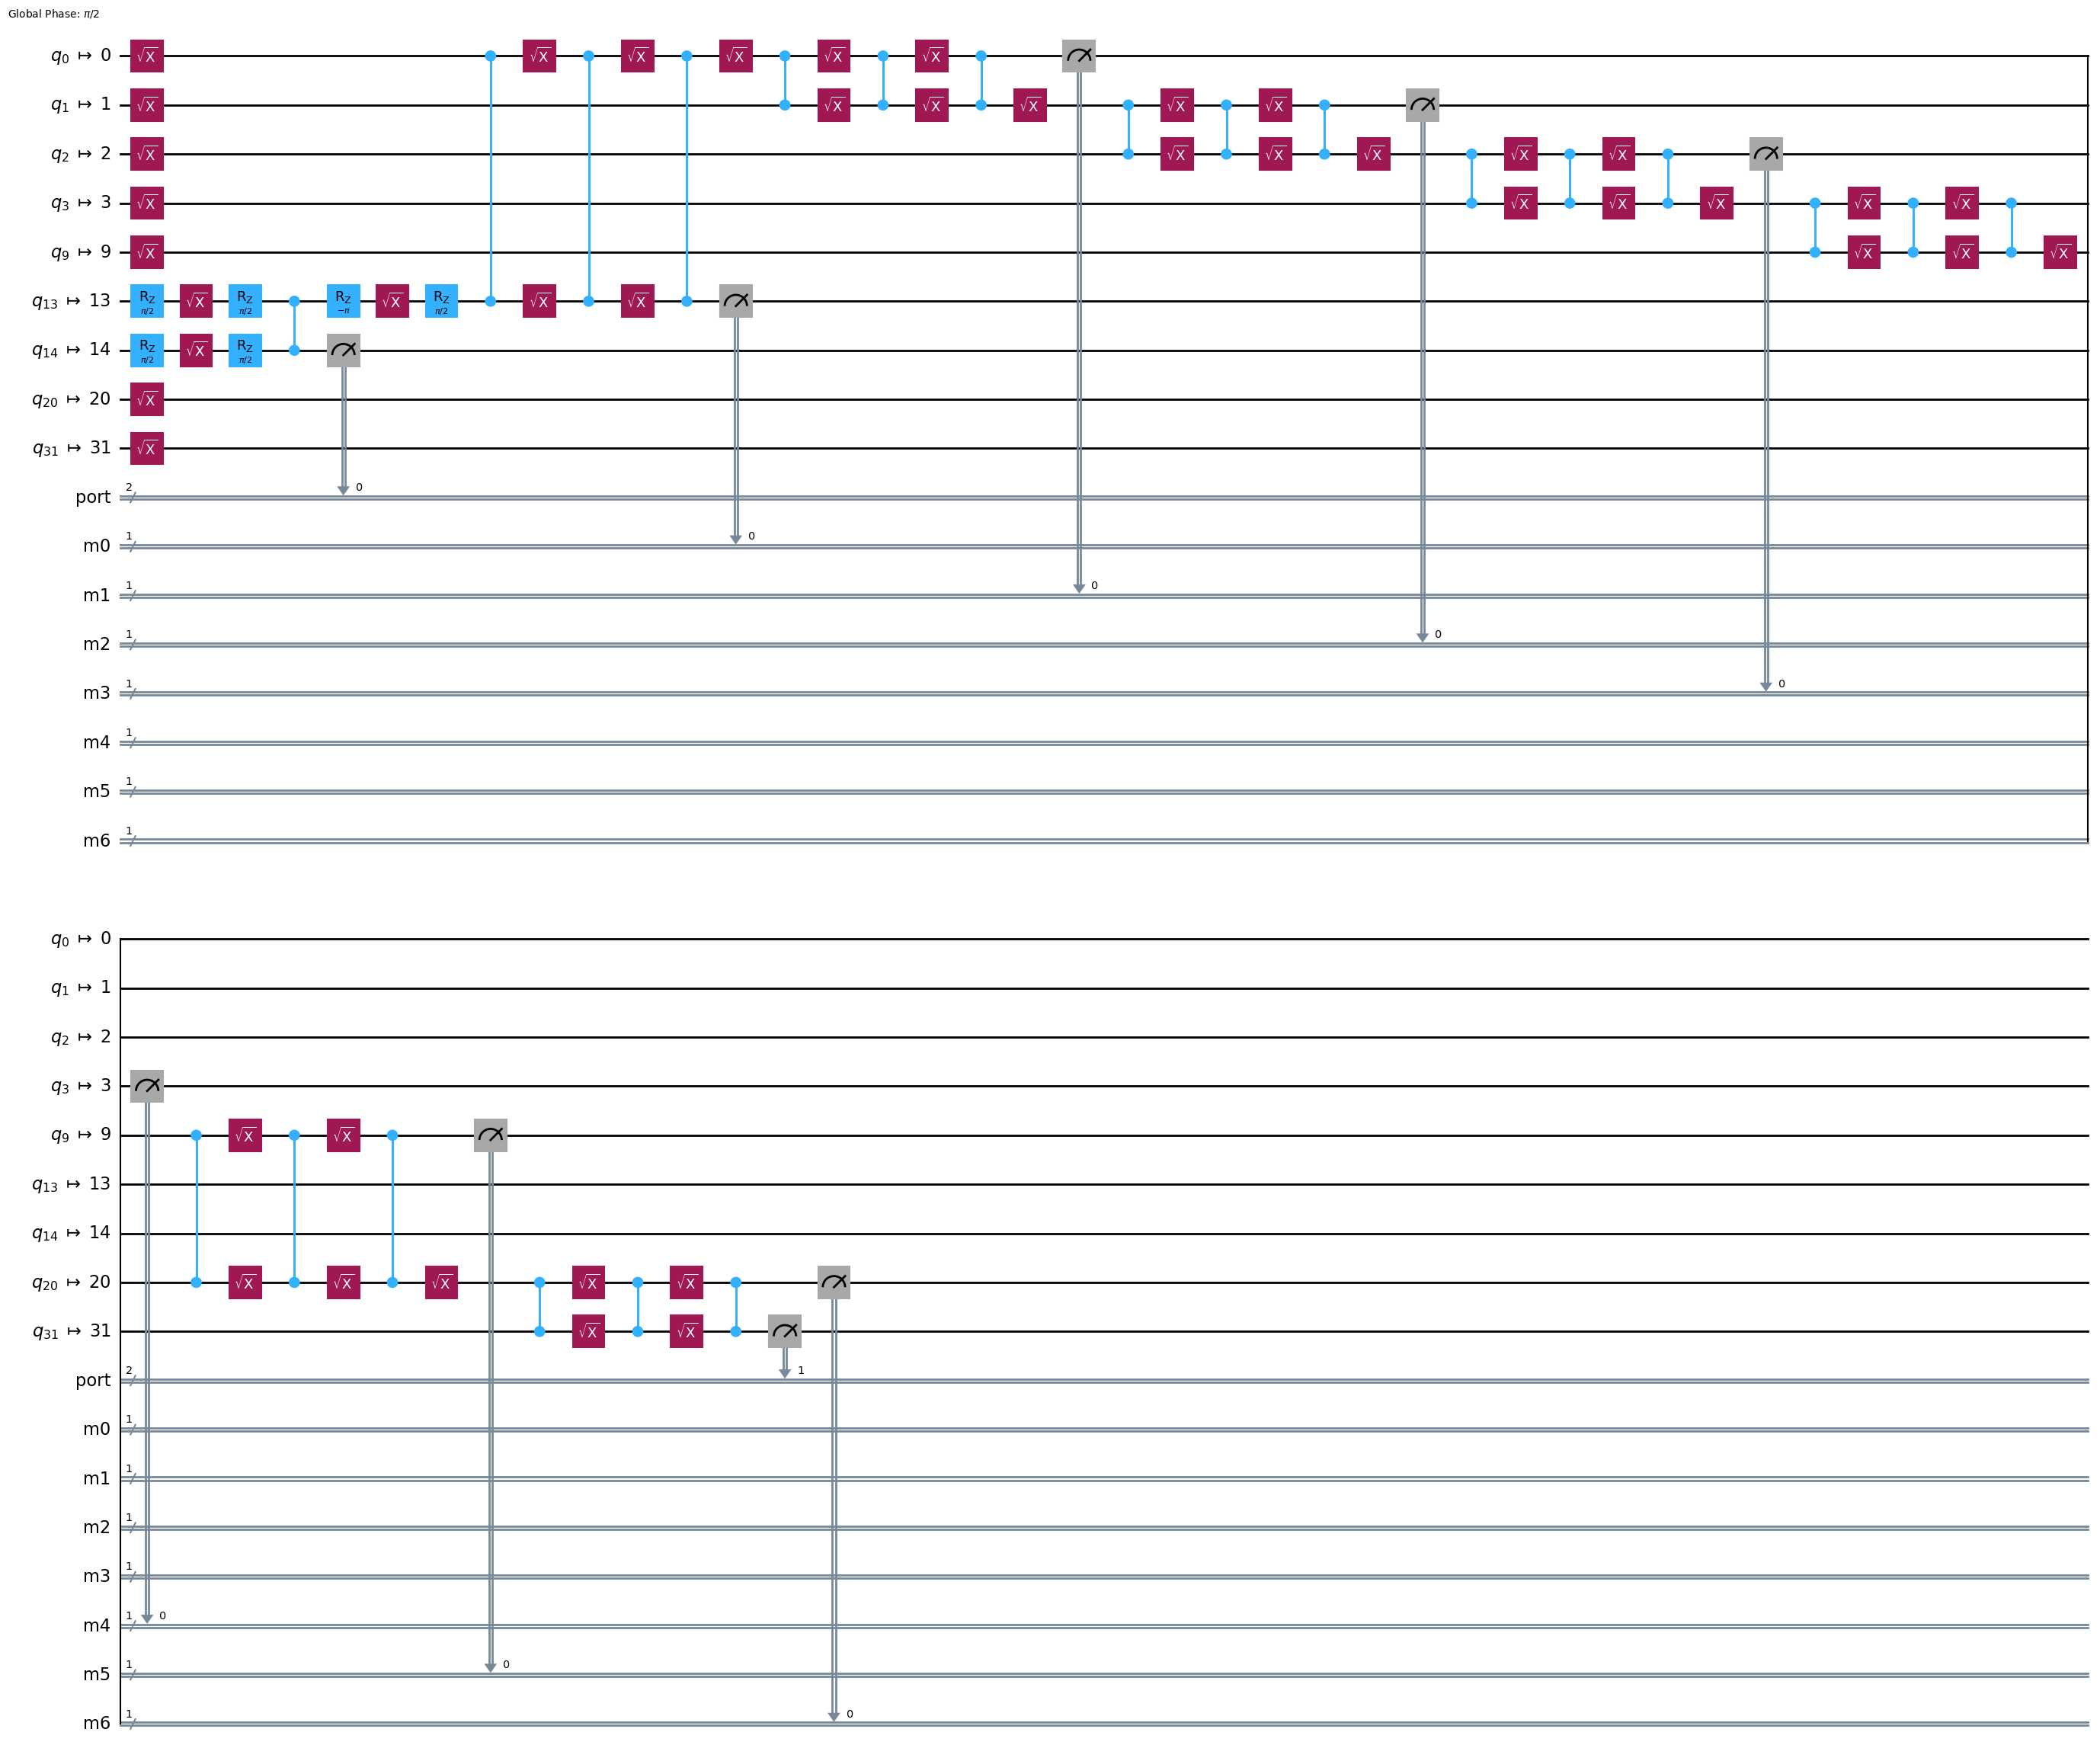

In [ ]:
show_circuit(PROCESSORS["hyperbolic"], PROTECTED_TRANSPORT, PROTECTION)

## 7. Playground

Optional studies. Nothing below feeds the core table.

### 7a. Strategy grid on one model

In [ ]:
def strategy_grid(proc, protections=([], ["vacancy"], ["bus_zz"], ["bus_xx"], ["bus_zz", "bus_xx"]), **kw):
    rows = []
    for t in TRANSPORTS:
        for prot in protections:
            try:
                rows.append(run_case(proc, t, prot, **kw))
            except Incompatible:
                pass
    cols = ["transport", "protection", "F", "F_err", "accept", "twoq", "depth", "swaps", "ancillas", "at_ports"]
    return pd.DataFrame(rows)[cols].sort_values("F", ascending=False).reset_index(drop=True)


strategy_grid(PROCESSORS["hyperbolic"])

,transport,protection,F,F_err,accept,twoq,depth,swaps,ancillas,at_ports
0,ghz_uncompute,vacancy,0.9607,0.0016,0.8998,15,64,0,7,True
1,ghz_uncompute,bus_xx,0.9506,0.0018,0.9012,23,89,0,7,True
2,swap_chain,bus_zz+bus_xx,0.9468,0.0020,0.8034,38,73,7,7,True
3,swap_middle_out,bus_zz+bus_xx,0.9461,0.0020,0.8047,38,71,7,7,True
4,ghz_uncompute,bus_zz+bus_xx,0.9444,0.0020,0.8545,17,53,0,7,True
5,ghz_uncompute,none,0.9415,0.0019,1.0000,15,63,0,7,True
6,swap_middle_out,vacancy,0.9399,0.0020,0.8992,22,31,7,7,True
7,swap_chain,vacancy,0.9399,0.0020,0.8992,22,49,7,7,True
8,swap_chain,bus_xx,0.9393,0.0020,0.8877,30,60,7,7,True
9,swap_middle_out,bus_xx,0.9393,0.0020,0.8877,30,54,7,7,True


### 7b. Same noise, different graph

The three core models differ in graph, gate set and noise at once. Here the noise and gate set
are pinned (`NOISE_MODERN`, CZ) so only connectivity varies. First the cost of reaching a port
at a given hop count, then how many hops each graph actually needs.

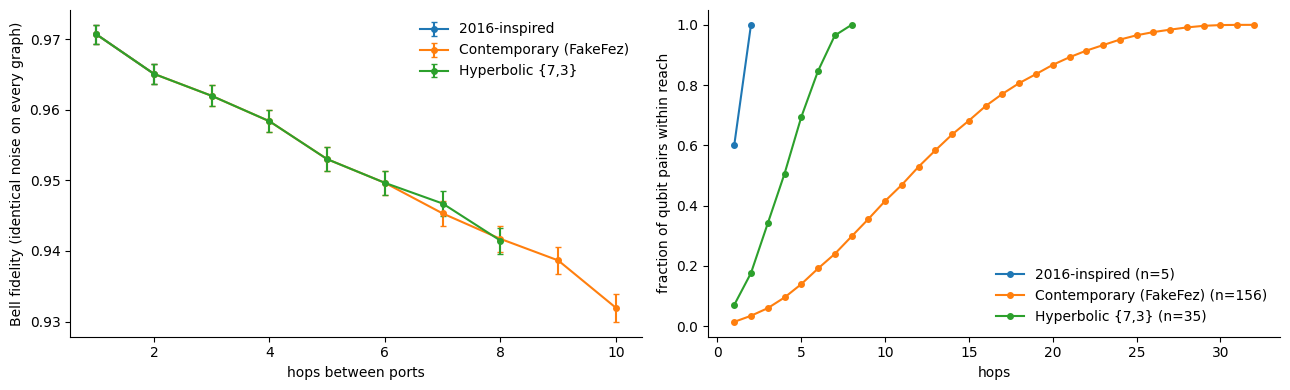

In [ ]:
def distance_sweep(procs, transport="ghz_uncompute", protection=(), noise=NOISE_MODERN, max_hops=10):
    rows = []
    for proc in procs.values():
        same = proc.with_noise(noise)
        for d in range(1, min(nx.diameter(proc.graph), max_hops) + 1):
            try:
                r = run_case(same.with_ports(*pair_at_distance(proc.graph, d)), transport, protection)
                rows.append(r)
            except (Incompatible, ValueError):
                pass
    return pd.DataFrame(rows)


sweep = distance_sweep(PROCESSORS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for model, sub in sweep.groupby("model", sort=False):
    ax1.errorbar(sub.hops, sub.F, yerr=sub.F_err, marker="o", ms=4, capsize=2, label=model)
ax1.set_xlabel("hops between ports")
ax1.set_ylabel("Bell fidelity (identical noise on every graph)")
ax1.legend(frameon=False)
for p in PROCESSORS.values():
    d = np.array([k for _, row in nx.all_pairs_shortest_path_length(p.graph) for k in row.values() if k])
    ax2.plot(np.arange(1, d.max() + 1), np.bincount(d)[1:].cumsum() / len(d), marker="o", ms=4,
             label=f"{p.label} (n={p.n})")
ax2.set_xlabel("hops")
ax2.set_ylabel("fraction of qubit pairs within reach")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### 7c. Where does protection start paying for itself?

Scale the synthetic noise and compare a baseline with a protected strategy on one graph.

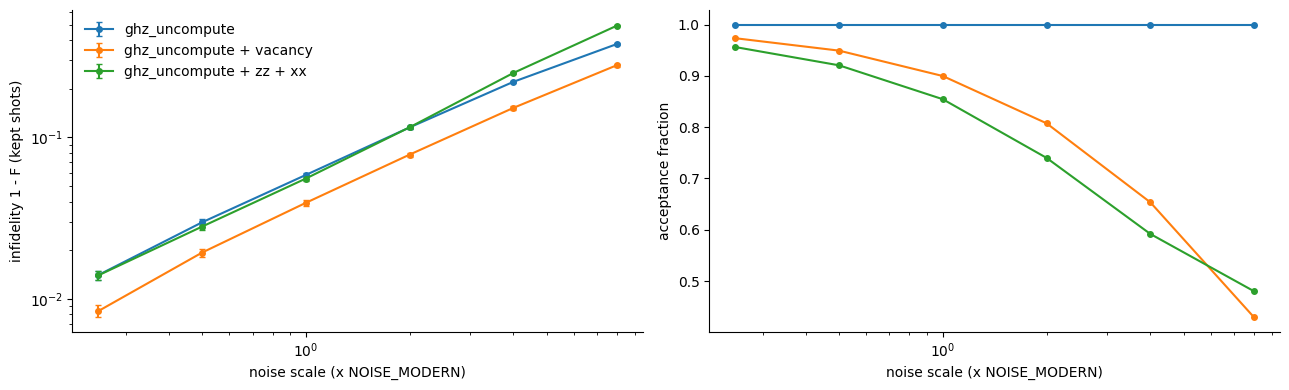

In [ ]:
def noise_sweep(proc, strategies, scales=(0.25, 0.5, 1, 2, 4, 8), base=NOISE_MODERN):
    rows = []
    for k in scales:
        scaled = proc.with_noise(base.scaled(k))
        for name, (t, prot) in strategies.items():
            rows.append(dict(scale=k, strategy=name, **run_case(scaled, t, prot)))
    return pd.DataFrame(rows)


ns = noise_sweep(PROCESSORS["hyperbolic"], {
    "ghz_uncompute": ("ghz_uncompute", []),
    "ghz_uncompute + vacancy": ("ghz_uncompute", ["vacancy"]),
    "ghz_uncompute + zz + xx": ("ghz_uncompute", ["bus_zz", "bus_xx"]),
})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, sub in ns.groupby("strategy", sort=False):
    ax1.errorbar(sub.scale, 1 - sub.F, yerr=sub.F_err, marker="o", ms=4, capsize=2, label=name)
    ax2.plot(sub.scale, sub.accept, marker="o", ms=4, label=name)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax2.set_xscale("log")
ax1.set_xlabel("noise scale (x NOISE_MODERN)"); ax1.set_ylabel("infidelity 1 - F (kept shots)")
ax2.set_xlabel("noise scale (x NOISE_MODERN)"); ax2.set_ylabel("acceptance fraction")
ax1.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### 7d. What if the qubits were noise-biased?

Several emerging qubit designs (cat qubits, dual-rail erasure qubits, replacement-type gates) look the same at circuit level: phase errors dominate, and ideally the CX keeps it that way.

This section asks what that would do to the Bell pair. It is a hardware what-if and is kept separate from the common benchmark.

`BiasedNoise` has two knobs: the bias `eta = p_Z / (p_X + p_Y)`, and whether the CX preserves it. Every gate keeps the same total error probability as `NOISE_MODERN` and readout error is unchanged, so only the mix of X, Y and Z differs from sections 7b and 7c.

Both reuse the axes of 7c and 7b, in three columns that share them:

| Column | Noise |
|---|---|
| Left | Unbiased reference, redrawn from 7b and 7c |
| Middle | `eta = 100`, CX native and bias-preserving |
| Right | `eta = 100`, CX compiled as H.CZ.H, where the Hadamards turn Z errors into X errors |

- **First figure:** infidelity and acceptance against noise scale, on the hyperbolic graph.
  The dotted line is the infidelity from readout error on the two ports alone, which no check can remove.
- **Second figure:** Bell fidelity against hops on all three graphs. Solid lines have no check;
  dashed lines add the XX check (`bus_xx`).
- **Tables:** the same results at noise scale 1, and against hops with the XX check on.

With a bias-preserving CX the pair only sees phase errors, so `vacancy`
(a ZZ-type check) has nothing to catch and a single `bus_xx` should do the work. Distance should
then cost acceptance instead of fidelity. In the right column the bias is scrambled, and both
kinds of check are needed again.

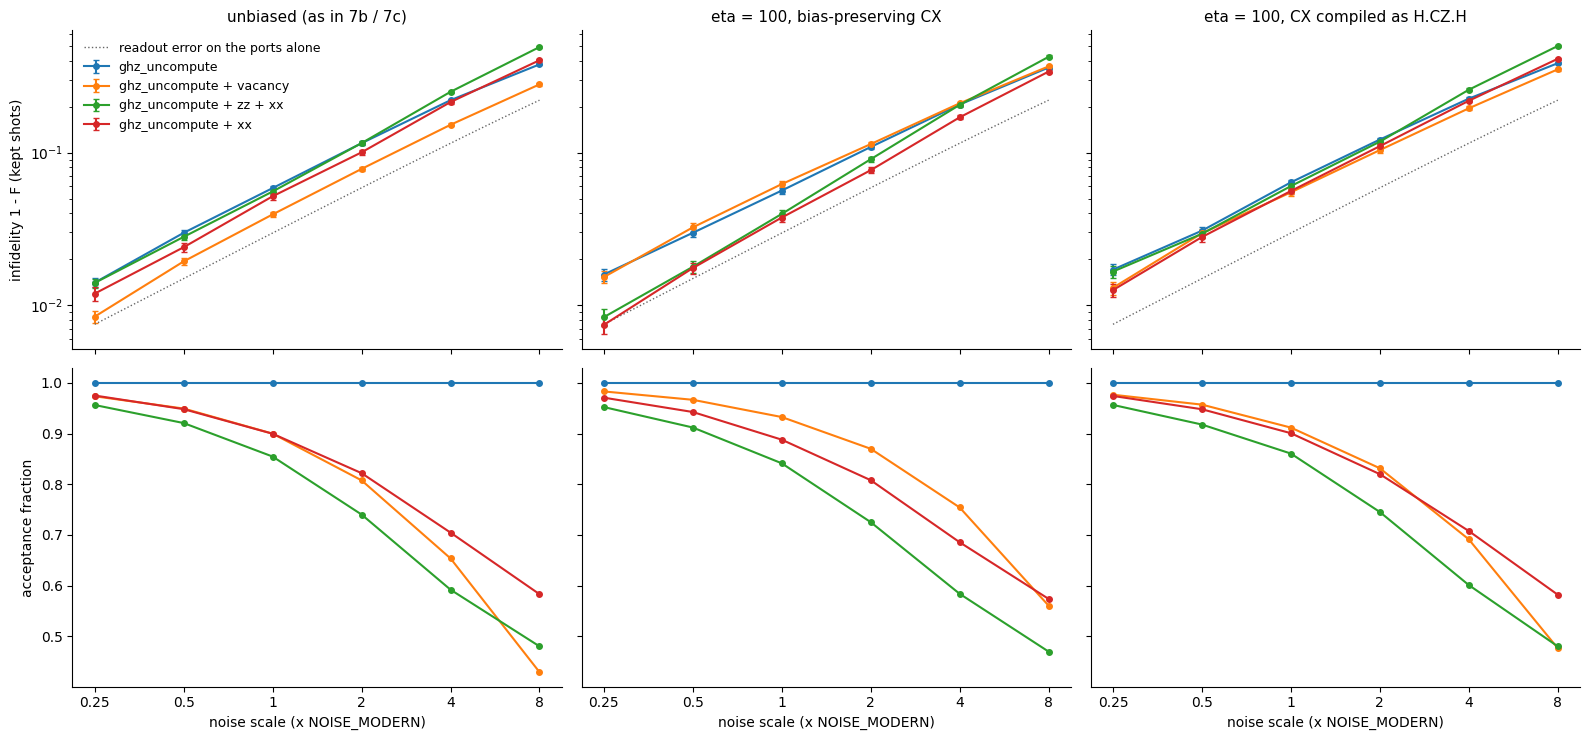

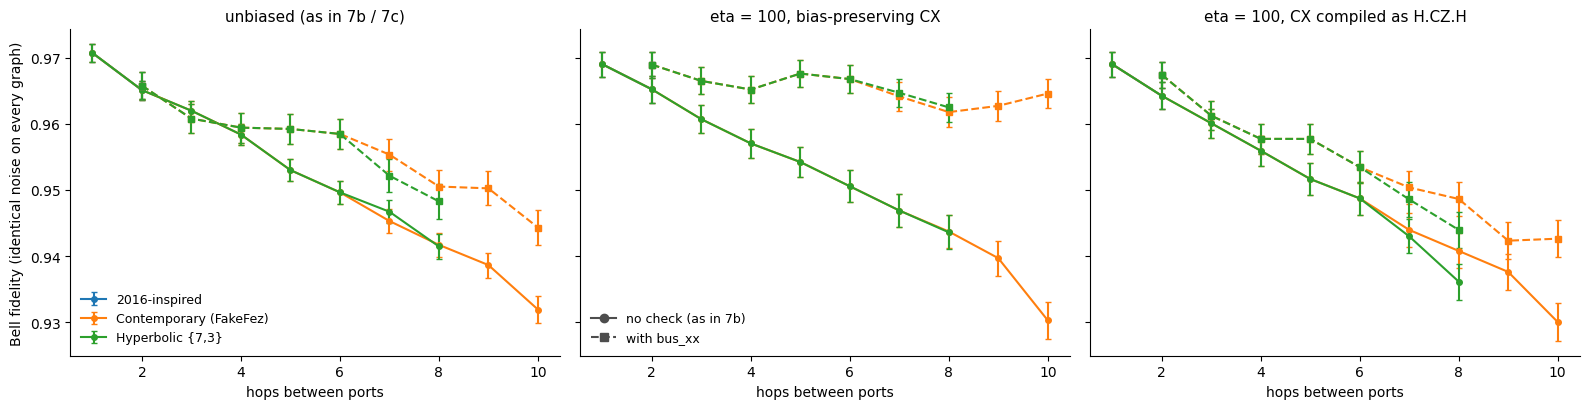

unbiased (as in 7b / 7c)         eta = 100, bias-preserving CX         eta = 100, CX compiled as H.CZ.H        
                                               F  accept                             F  accept                                F  accept
strategy                                                                                                                               
ghz_uncompute                             0.9415  1.0000                        0.9436  1.0000                           0.9362  1.0000
ghz_uncompute + vacancy                   0.9607  0.8998                        0.9378  0.9325                           0.9451  0.9117
ghz_uncompute + zz + xx                   0.9444  0.8545                        0.9604  0.8412                           0.9397  0.8604
ghz_uncompute + xx                        0.9483  0.8996                        0.9625  0.8879                           0.9440  0.9006

unbiased (as in 7b / 7c)         eta = 100, bias-preserving CX         eta = 100, CX compiled as H.CZ.H        
                            F  accept                             F  accept                                F  accept
hops                                                                                                                
2                      0.9658  0.9806                        0.9689  0.9784                           0.9674  0.9778
3                      0.9608  0.9682                        0.9665  0.9648                           0.9612  0.9666
4                      0.9594  0.9542                        0.9652  0.9501                           0.9577  0.9534
5                      0.9592  0.9399                        0.9676  0.9337                           0.9577  0.9386
6                      0.9585  0.9257                        0.9668  0.9180                           0.9535  0.9255
7                      0.9522  0.9141                        0.9647  0.9053                           0.9486  0.9128
8                      0.9483  0.8996                        0.9625  0.8879                           0.9440  0.9006

In [ ]:
from dataclasses import dataclass, replace
from qiskit_aer.noise import NoiseModel, ReadoutError, pauli_error


def _with_noise(self, noise, label=None):
    return replace(self, noise=noise, backend=None, label=label or self.label, _sims={},
                   two_qubit_gate=getattr(noise, "two_qubit_gate", "cz"))


Processor.with_noise = _with_noise     # honour the noise model's native two-qubit gate


@dataclass
class BiasedNoise:
    """Effective model of a noise-biased qubit (cat, 0-n Fock, post-selected dual-rail, or a
    replacement-type gate): Pauli errors with p_Z = eta * (p_X + p_Y). eta = 0.5 is unbiased.

    bias_preserving=True  -> CX is a native gate, so a Z error stays a Z error.
    bias_preserving=False -> CX is compiled as H.CZ.H and the Hadamards turn Z into X.
    p2 is the total error probability per two-qubit gate, split evenly over its two qubits."""
    p1: float
    p2: float
    readout: float
    eta: float = 100.0
    bias_preserving: bool = True

    @classmethod
    def like(cls, ref, eta=100.0, bias_preserving=True):
        """Same total error probability per gate and same readout error as a SyntheticNoise;
        only the mix of X, Y and Z changes. (A depolarising parameter p leaves the state
        untouched with probability p/4 for one qubit and p/16 for two, hence the factors.)"""
        return cls(p1=0.75 * ref.p1, p2=0.9375 * ref.p2, readout=ref.readout,
                   eta=eta, bias_preserving=bias_preserving)

    @property
    def two_qubit_gate(self):
        return "cx" if self.bias_preserving else "cz"

    def scaled(self, k):
        return replace(self, p1=min(self.p1 * k, 0.75), p2=min(self.p2 * k, 0.9),
                       readout=min(self.readout * k, 0.5))

    def _pauli(self, p):
        px = p / (2 * (self.eta + 1))
        return pauli_error([("X", px), ("Y", px), ("Z", p - 2 * px), ("I", 1 - p)])

    def build(self, two_qubit_gate):
        nm = NoiseModel(basis_gates=["rz", "sx", "x", two_qubit_gate])
        nm.add_all_qubit_quantum_error(self._pauli(self.p1), ["sx", "x"])
        e = self._pauli(self.p2 / 2)
        nm.add_all_qubit_quantum_error(e.tensor(e), [two_qubit_gate])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - self.readout, self.readout],
                                                     [self.readout, 1 - self.readout]]))
        return nm


def distance_sweep(procs, transport="ghz_uncompute", protection=(), noise=NOISE_MODERN, max_hops=10, **kw):
    rows = []
    for proc in procs.values():
        same = proc.with_noise(noise)
        for d in range(1, min(nx.diameter(proc.graph), max_hops) + 1):
            try:
                r = run_case(same.with_ports(*pair_at_distance(proc.graph, d)), transport, protection, **kw)
                rows.append(r)
            except (Incompatible, ValueError):
                pass
    return pd.DataFrame(rows)


def scale_axis(ax, scales):
    """Log x axis with one plain tick per simulated noise scale."""
    ax.set_xscale("log")
    ax.set_xticks(list(scales), [f"{k:g}" for k in scales])
    ax.tick_params(axis="x", which="minor", bottom=False, labelbottom=False)
    ax.set_xlabel("noise scale (x NOISE_MODERN)")


def noise_sweep(proc, strategies, scales=(0.25, 0.5, 1, 2, 4, 8), base=NOISE_MODERN, **kw):
    rows = []
    for k in scales:
        scaled = proc.with_noise(base.scaled(k))
        for name, (t, prot) in strategies.items():
            rows.append(dict(scale=k, strategy=name, **run_case(scaled, t, prot, **kw)))
    return pd.DataFrame(rows)


# Reference results from 7b and 7c, reused if already in memory.
if "sweep" not in globals():
    sweep = distance_sweep(PROCESSORS)
if "ns" not in globals():
    ns = noise_sweep(PROCESSORS["hyperbolic"], {
        "ghz_uncompute": ("ghz_uncompute", []),
        "ghz_uncompute + vacancy": ("ghz_uncompute", ["vacancy"]),
        "ghz_uncompute + zz + xx": ("ghz_uncompute", ["bus_zz", "bus_xx"]),
    })

from matplotlib.lines import Line2D

ETA = 100                                           # noise bias p_Z / (p_X + p_Y); 0.5 is unbiased
BIAS_SHOTS = 4096                                   # per basis; halves the runtime of this block
REFERENCE = "unbiased (as in 7b / 7c)"
BIASED = {
    f"eta = {ETA}, bias-preserving CX": BiasedNoise.like(NOISE_MODERN, ETA, bias_preserving=True),
    f"eta = {ETA}, CX compiled as H.CZ.H": BiasedNoise.like(NOISE_MODERN, ETA, bias_preserving=False),
}
# First three match 7c (same names, same order, so same colours); the fourth is the one that matters here.
BIAS_STRATEGIES = {
    "ghz_uncompute": ("ghz_uncompute", []),
    "ghz_uncompute + vacancy": ("ghz_uncompute", ["vacancy"]),
    "ghz_uncompute + zz + xx": ("ghz_uncompute", ["bus_zz", "bus_xx"]),
    "ghz_uncompute + xx": ("ghz_uncompute", ["bus_xx"]),
}
hyp = PROCESSORS["hyperbolic"]

# --- Axes of 7c: infidelity and acceptance against noise scale -------------------------------
scales = tuple(sorted(ns.scale.unique()))
missing = {k: v for k, v in BIAS_STRATEGIES.items() if k not in set(ns.strategy)}
scale_panels = {REFERENCE: pd.concat([ns, noise_sweep(hyp, missing, scales=scales, shots=BIAS_SHOTS)]) if missing else ns}
for title, noise in BIASED.items():
    scale_panels[title] = noise_sweep(hyp, BIAS_STRATEGIES, scales=scales, base=noise, shots=BIAS_SHOTS)

fig, axes = plt.subplots(2, len(scale_panels), figsize=(16, 7.5), sharex=True, sharey="row")
ks = np.geomspace(min(scales), max(scales), 50)
floor = 0.75 * (1 - (1 - 2 * np.minimum(NOISE_MODERN.readout * ks, 0.5)) ** 2)
for col, (title, df) in enumerate(scale_panels.items()):
    top, bottom = axes[0, col], axes[1, col]
    for name in BIAS_STRATEGIES:
        sub = df[df.strategy == name]
        top.errorbar(sub.scale, 1 - sub.F, yerr=sub.F_err, marker="o", ms=4, capsize=2, label=name)
        bottom.plot(sub.scale, sub.accept, marker="o", ms=4, label=name)
    top.plot(ks, floor, ls=":", lw=1, color="0.4", label="readout error on the ports alone")
    scale_axis(top, scales)
    scale_axis(bottom, scales)
    top.set_xlabel("")
    top.set_yscale("log")
    top.set_title(title, fontsize=11)
axes[0, 0].set_ylabel("infidelity 1 - F (kept shots)")
axes[1, 0].set_ylabel("acceptance fraction")
axes[0, 0].legend(frameon=False, fontsize=9)
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# --- Axes of 7b: Bell fidelity against hops, identical noise on every graph ------------------
xx = dict(protection=["bus_xx"], shots=BIAS_SHOTS)
hop_panels = {REFERENCE: {"none": sweep, "bus_xx": distance_sweep(PROCESSORS, **xx)}}
for title, noise in BIASED.items():
    hop_panels[title] = {"none": distance_sweep(PROCESSORS, noise=noise, shots=BIAS_SHOTS),
                         "bus_xx": distance_sweep(PROCESSORS, noise=noise, **xx)}

model_color = {m: f"C{i}" for i, m in enumerate(sweep.model.unique())}
style = {"none": dict(ls="-", marker="o"), "bus_xx": dict(ls="--", marker="s")}
fig, axes = plt.subplots(1, len(hop_panels), figsize=(16, 4.2), sharex=True, sharey=True)
for ax, (title, runs) in zip(axes, hop_panels.items()):
    for prot, df in runs.items():
        for model, sub in df.groupby("model", sort=False):
            ax.errorbar(sub.hops, sub.F, yerr=sub.F_err, ms=4, capsize=2, color=model_color[model],
                        label=model if prot == "none" else None, **style[prot])
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("hops between ports")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Bell fidelity (identical noise on every graph)")
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
axes[1].legend(handles=[Line2D([], [], color="0.3", label="no check (as in 7b)", **style["none"]),
                        Line2D([], [], color="0.3", label="with bus_xx", **style["bus_xx"])],
               frameon=False, fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

# Numbers behind the two figures, on the hyperbolic graph: every strategy at noise scale 1,
# then fidelity and shots kept against hops with the XX check on.
at_scale_1 = pd.concat({t: df[df.scale == 1].set_index("strategy")[["F", "accept"]]
                        for t, df in scale_panels.items()}, axis=1).loc[list(BIAS_STRATEGIES)]
by_hops = pd.concat({t: runs["bus_xx"][runs["bus_xx"].model == hyp.label].set_index("hops")[["F", "accept"]]
                     for t, runs in hop_panels.items()}, axis=1)
display(at_scale_1, by_hops)

## 7e. Replacement-style gates

After Ginzel, Kazemi, Torggler, Lechner, "Replacement-Type Quantum Gates", arXiv:2508.00437.

The idea, Sec. II of the paper: never rotate the qubit. Prepare "candidate" qubits in the states the gate should produce, let the input qubit decide which candidate ends up on the output site (coherent rearrangement), then measure everything except the output in the |+>, |-> basis (disentangling). The output holds U|q> up to a Z that the outcomes tell you.

What this models: the logic of the protocol and how errors travel through it.
What it does not: the spin or atom physics (blockade, tunnelling, charge noise, empty sites).
Each site here is one qubit and a conditional displacement is one controlled-SWAP.

replacement X     fidelity 1.000000 (deferred)  1.000000 (256 sampled measurement records)
replacement CNOT  fidelity 1.000000 (deferred)  1.000000 (256 sampled measurement records)
CNOT as H.CZ.H    fidelity 1.000000 (deferred)  1.000000 (256 sampled measurement records)

Replacement-type X: input on q0, output on q1, auxiliary site q2
      ┌───────┐   ┌───┐┌─┐                                                         
 q_0: ┤ Ry(1) ├─■─┤ H ├┤M├─────────────────────────────────────────────────────────
      └─┬───┬─┘ │ └───┘└╥┘     ┌──────   ┌───┐ ───────┐   ┌──────   ┌───┐ ───────┐ 
 q_1: ──┤ X ├───X───────╫──────┤ If-0  ──┤ Z ├  End-0 ├───┤ If-0  ──┤ Z ├  End-0 ├─
        └───┘   │ ┌───┐ ║ ┌─┐  └──╥───   └───┘ ───────┘   └──╥───   └───┘ ───────┘ 
 q_2: ──────────X─┤ H ├─╫─┤M├─────╫──────────────────────────╫─────────────────────
                  └───┘ ║ └╥┘┌────╨─────┐                    ║                     
m0: 1/══════════════════╩══╬═╡ m0_0=0x1 ╞════════════════════╬═══════════

,X fault,Z fault
candidate preparation,BIT ERROR,no effect
rearrangement,BIT ERROR,phase error only
disentangling,no effect,phase error only
readout,phase error only,no effect



CNOT as H.CZ.H: effect of one fault on the output


,X fault,Z fault
first Hadamard,phase error only,BIT ERROR
CZ,BIT ERROR,BIT ERROR
second Hadamard,BIT ERROR,phase error only



Error budget with ReplacementNoise(p_init=0.001, p_move_z=0.003, p_move_x=0.0001, p_disent=0.0001, p_meas=0.001)


,fidelity,phase_error,bit_error,bias,"fidelity, rearrangement only","paper, rearrangement only"
replacement X,0.9874,0.0115,0.0011,10.4704,0.9895,0.9891
replacement CNOT,0.9660,0.0316,0.0024,13.1634,0.9701,0.9265
CNOT as H.CZ.H,0.9877,0.0062,0.0062,0.9955,0.9877,NaN


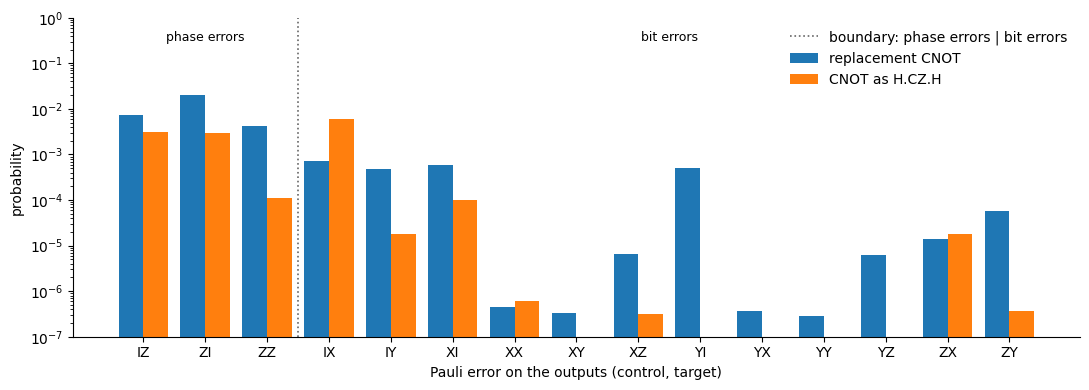


BiasedNoise(..., p2=0.0340, eta=13, bias_preserving=True)


In [ ]:
# Replacement-type quantum gates in Qiskit, at the logic level.
# After Ginzel, Kazemi, Torggler, Lechner, "Replacement-Type Quantum Gates", arXiv:2508.00437.
#
# Paste into one notebook cell and run. Needs only qiskit and qiskit-aer; it does not depend on
# the hackathon template.
#
# The idea, Sec. II of the paper: never rotate the qubit. Prepare "candidate" qubits in the
# states the gate should produce, let the input qubit decide which candidate ends up on the
# output site (coherent rearrangement), then measure everything except the output in the
# |+>, |-> basis (disentangling). The output holds U|q> up to a Z that the outcomes tell you.
#
# What this models: the logic of the protocol and how errors travel through it.
# What it does not: the spin or atom physics (blockade, tunnelling, charge noise, empty sites).
# Each site here is one qubit and a conditional displacement is one controlled-SWAP.
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import ClassicalRegister, QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import pauli_error

try:
    display
except NameError:                     # running as a plain script
    display = print


# ---------------------------------------------------------------------------------------------
# 1. Where errors enter
# ---------------------------------------------------------------------------------------------
@dataclass
class ReplacementNoise:
    p_init: float = 1e-3       # a candidate is prepared in the wrong basis state   (paper: 1 - p_i)
    p_move_z: float = 3e-3     # dephasing, per site per conditional displacement   (free knob, see 5)
    p_move_x: float = 1e-4     # bit flip, per site per conditional displacement    (free knob)
    p_disent: float = 1e-4     # unbiased error on a discarded site before readout  (paper: EDSR gate)
    p_meas: float = 1e-3       # wrong outcome of a disentangling measurement       (paper: charge readout)


NOISELESS = ReplacementNoise(0, 0, 0, 0, 0)


# ---------------------------------------------------------------------------------------------
# 2. The gates
# ---------------------------------------------------------------------------------------------
class ReplacementGates:
    """Appends replacement-type gates to a circuit.

    A gate consumes its inputs: the logical state leaves on the output sites, and every other
    site it touched has been measured, so it can be reset and reused.

    deferred=True replaces each measurement + conditional Z by a CZ. That is the same channel
    without sampling outcomes, which is what the exact analysis below uses.
    fault=(k, "X") puts one deliberate Pauli at the k-th error location instead of random noise.
    """

    def __init__(self, qc, noise=NOISELESS, deferred=False, fault=None):
        self.qc, self.noise, self.deferred, self.fault = qc, noise, deferred, fault
        self.locations = []                      # (stage, qubit) of every place an error can enter

    def _errors(self, stage, qubits, **probs):
        for q in qubits:
            self.locations.append((stage, q))
            if self.fault is not None:
                if self.fault[0] == len(self.locations) - 1:
                    getattr(self.qc, self.fault[1].lower())(q)
                continue
            terms = [(pauli, p) for pauli, p in probs.items() if p > 0]
            if terms:
                self.qc.append(pauli_error(terms + [("I", 1 - sum(p for _, p in terms))]), [q])

    # --- primitives ---------------------------------------------------------------------------
    def candidate(self, site, bit):
        """A candidate qubit, prepared in a basis state on its site (the site starts in |0>)."""
        if bit:
            self.qc.x(site)
        self._errors("candidate preparation", [site], X=self.noise.p_init)

    def displace(self, control, a, b):
        """Coherent rearrangement: the occupants of sites a and b trade places if control is 1."""
        self.qc.cswap(control, a, b)
        self._errors("rearrangement", [control, a, b], Z=self.noise.p_move_z, X=self.noise.p_move_x)

    def disentangle(self, site, outputs):
        """Measure a discarded site in the |+>, |-> basis. Outcome 1 means a Z is owed on `outputs`."""
        third = self.noise.p_disent / 3
        self._errors("disentangling", [site], X=third, Y=third, Z=third)
        self.qc.h(site)
        self._errors("readout", [site], X=self.noise.p_meas)
        if self.deferred:
            for out in outputs:
                self.qc.cz(site, out)
        else:
            bit = ClassicalRegister(1, f"m{len(self.qc.clbits)}")
            self.qc.add_register(bit)
            self.qc.measure(site, bit[0])
            with self.qc.if_test((bit[0], 1)):
                for out in outputs:
                    self.qc.z(out)

    # --- replacement-type gates -----------------------------------------------------------------
    def x(self, q, out, aux):
        """X gate. Sites `out` and `aux` start in |0>. The logical qubit leaves on `out`."""
        self.candidate(out, 1)                   # |0_U> = X|0>, already sitting on the output site
        self.candidate(aux, 0)                   # |1_U> = X|1>
        self.displace(q, out, aux)               # Eqs. (2)-(3): the input picks the candidate
        self.disentangle(q, [out])               # Eqs. (5)-(6)
        self.disentangle(aux, [out])             # Eq. (7)
        return out

    def cx(self, c, t, out_c, aux_c, out_t, aux_t):
        """CNOT. The four extra sites start in |0>. The logical qubits leave on out_c, out_t."""
        for site, bit in [(out_c, 0), (aux_c, 1), (out_t, 0), (aux_t, 1)]:
            self.candidate(site, bit)
        self.displace(c, out_c, aux_c)           # out_c reads c
        self.displace(c, out_t, aux_t)           # the target's candidates trade places once per
        self.displace(t, out_t, aux_t)           # excited input; two trades cancel: out_t reads c XOR t
        self.disentangle(c, [out_c])
        self.disentangle(aux_c, [out_c])
        self.disentangle(t, [out_c, out_t])
        self.disentangle(aux_t, [out_t])
        return out_c, out_t

    # --- the conventional construction, for comparison ----------------------------------------
    def standard_cx(self, c, t):
        """CNOT = H.CZ.H on the target, with the same per-site noise after every operation."""
        z, x = self.noise.p_move_z, self.noise.p_move_x
        self.qc.h(t)
        self._errors("first Hadamard", [t], Z=z, X=x)
        self.qc.cz(c, t)
        self._errors("CZ", [c, t], Z=z, X=x)
        self.qc.h(t)
        self._errors("second Hadamard", [t], Z=z, X=x)
        return c, t


# ---------------------------------------------------------------------------------------------
# 3. Exact error channel of a gate, from its Choi state
# ---------------------------------------------------------------------------------------------
GATES = {   # name: (logical qubits, extra sites, ideal gate, how to build it)
    "replacement X": (1, 2, lambda qc, d: qc.x(d[0]), lambda g, q, s: [g.x(q[0], *s)]),
    "replacement CNOT": (2, 4, lambda qc, d: qc.cx(d[0], d[1]), lambda g, q, s: list(g.cx(q[0], q[1], *s))),
    "CNOT as H.CZ.H": (2, 0, lambda qc, d: qc.cx(d[0], d[1]), lambda g, q, s: list(g.standard_cx(q[0], q[1]))),
}
_DM = AerSimulator(method="density_matrix")


def channel(name, noise=NOISELESS, fault=None, deferred=True, shots=1):
    """Probability of each Pauli error on the outputs (control first, then target).

    Each input is half of a Bell pair with a reference qubit, so the final state of
    references + outputs is the gate's Choi state and its overlaps with the ideal one,
    shifted by each Pauli, are the error rates. Returns (rates, error locations)."""
    n, extra, ideal_gate, build = GATES[name]
    refs, inputs, spare = range(n), list(range(n, 2 * n)), list(range(2 * n, 2 * n + extra))
    qc = QuantumCircuit(2 * n + extra)
    for r, q in zip(refs, inputs):
        qc.h(r)
        qc.cx(r, q)
    g = ReplacementGates(qc, noise, deferred, fault)
    outputs = build(g, inputs, spare)
    qc.save_density_matrix(qubits=list(refs) + list(outputs), label="rho")
    rho = _DM.run(transpile(qc, _DM, optimization_level=0), shots=shots).result().data(0)["rho"].data

    ideal = QuantumCircuit(2 * n)
    for r in refs:
        ideal.h(r)
        ideal.cx(r, n + r)
    ideal_gate(ideal, inputs)
    phi = Statevector(ideal)
    rates = {}
    for label in (["I", "X", "Y", "Z"] if n == 1 else [a + b for a in "IXYZ" for b in "IXYZ"]):
        v = phi.evolve(Pauli(label[::-1]), qargs=inputs).data     # Qiskit labels read right to left
        rates[label] = float(np.real(v.conj() @ rho @ v))
    return pd.Series(rates), g.locations


def summarise(rates):
    """Fidelity, total phase-type and bit-type error, and the bias between them."""
    has_bit = [bool(set(k) & set("XY")) for k in rates.index]
    bit = rates[has_bit].sum()
    phase = 1 - bit - rates.iloc[0]
    return dict(fidelity=rates.iloc[0], phase_error=phase, bit_error=bit,
                bias=phase / bit if bit > 1e-12 else np.inf)


# ---------------------------------------------------------------------------------------------
# 4. Checks: the gates are exact without noise, in both forms
# ---------------------------------------------------------------------------------------------
for name in GATES:
    exact = channel(name)[0].iloc[0]                                   # deferred measurement
    sampled = channel(name, deferred=False, shots=256)[0].iloc[0]      # real measurements + feed-forward
    assert abs(exact - 1) < 1e-9 and abs(sampled - 1) < 1e-9, name
    print(f"{name:17s} fidelity {exact:.6f} (deferred)  {sampled:.6f} (256 sampled measurement records)")

demo = QuantumCircuit(3)
demo.ry(1.0, 0)                                    # some input state on qubit 0
ReplacementGates(demo).x(0, out=1, aux=2)
print("\nReplacement-type X: input on q0, output on q1, auxiliary site q2")
print(demo.draw(output="text", fold=120))


# ---------------------------------------------------------------------------------------------
# 5. How a single fault travels: what kind of error reaches the output?
# ---------------------------------------------------------------------------------------------
def fault_table(name):
    """Worst outcome of one Pauli fault at each stage: bit error, phase error only, or no effect."""
    locations = channel(name)[1]
    worst = {}
    for k, (stage, _) in enumerate(locations):
        for pauli in "XZ":
            s = summarise(channel(name, fault=(k, pauli))[0])
            rank = 2 if s["bit_error"] > 1e-9 else 1 if s["phase_error"] > 1e-9 else 0
            worst[stage, pauli] = max(rank, worst.get((stage, pauli), 0))
    words = ["no effect", "phase error only", "BIT ERROR"]
    table = pd.Series({k: words[v] for k, v in worst.items()}).unstack()
    table.columns = [f"{p} fault" for p in table.columns]
    return table.loc[list(dict.fromkeys(stage for stage, _ in locations))]


for name in ("replacement CNOT", "CNOT as H.CZ.H"):
    print(f"\n{name}: effect of one fault on the output")
    display(fault_table(name))


# ---------------------------------------------------------------------------------------------
# 6. With noise: error rates of each construction
# ---------------------------------------------------------------------------------------------
NOISE = ReplacementNoise()                 # edit the knobs here
rates = {name: channel(name, NOISE)[0] for name in GATES}
summary = pd.DataFrame({name: summarise(r) for name, r in rates.items()}).T
# The paper quotes fidelities for the rearrangement alone, so compute that too for a like-for-like column.
no_disentangling_errors = replace(NOISE, p_disent=0, p_meas=0)
summary["fidelity, rearrangement only"] = [channel(name, no_disentangling_errors)[0].iloc[0] for name in GATES]
summary["paper, rearrangement only"] = [0.98911, 0.92649, np.nan]      # Fig. 7, realistic parameters
print("\nError budget with", NOISE)
display(summary.round(5))

order = ["IZ", "ZI", "ZZ"] + [k for k in rates["replacement CNOT"].index if set(k) & set("XY")]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(order))
for i, name in enumerate(("replacement CNOT", "CNOT as H.CZ.H")):
    ax.bar(x + (i - 0.5) * 0.4, rates[name][order].clip(lower=1e-9), 0.4, label=name)
ax.axvline(2.5, color="0.4", lw=1.2, ls=":", label="boundary: phase errors | bit errors")
ax.text(1.0, 0.96, "phase errors", ha="center", va="top", fontsize=9, transform=ax.get_xaxis_transform())
ax.text(8.5, 0.96, "bit errors", ha="center", va="top", fontsize=9, transform=ax.get_xaxis_transform())
ax.set_yscale("log")
ax.set_ylim(1e-7, 1)
ax.set_xticks(x, order)
ax.set_xlabel("Pauli error on the outputs (control, target)")
ax.set_ylabel("probability")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# To carry a gate into the Bell-pair simulation, hand its two numbers to the template's
# BiasedNoise: p2 = 1 - fidelity, eta = bias, bias_preserving=True.
cnot = summary.loc["replacement CNOT"]
print(f"\nBiasedNoise(..., p2={1 - cnot.fidelity:.4f}, eta={cnot.bias:.0f}, bias_preserving=True)")

Notable outcome is that the replacement CNOT gates do not actually improve error rate on their own.